# Homework 03: Learning Curves and Training Workflow

#### Due Date: Sunday, September 20th at 11:59pm (with 2 hour plus 1 minute grace period)

#### The late policy is described in the DX 703 Syllabus. 

In this assignment, you will learn how to design, train, and evaluate neural networks by systematically exploring key design choices. Your focus will be on developing an effective **training workflow** — using learning curves and validation metrics to guide your decisions.

We'll again use the **Forest Cover Type (Covertype) dataset,** which has ~581k tabular records with 54 cartographic/topographic features (elevation, aspect, slope, soil and wilderness indicators) used to predict one of seven tree cover types in Colorado’s Roosevelt National Forest. 

We will start with a **baseline model** (two hidden layers of sizes 64 and 32), and gradually introduce and tune different hyperparameters. Each of the first five problems considers  different hyperparameter choices, and the last problem is your chance to use what you have learned to design your best model:

1. **Activation function** – Compare ReLU, sigmoid, and tanh to see which provides the best accuracy.
2. **Learning rate** – Explore a range of learning rates and identify which balances convergence speed and stability.
3. **Dropout** – Investigate how different dropout rates reduce overfitting and where they are most effective.
4. **L2 regularization** – Experiment with weight penalties to encourage simpler models and avoid memorization.
5. **Dropout + L2** – Combine both regularization techniques and study their interaction.
6. **Best model design** – Use all your insights to build and train your strongest model, with the option to try **learning rate scheduling** for further improvement.

In this homework, you will use **early stopping** to select the "best" model at the epoch of **minimum validation loss**, and you will report the **validation accuracy** of that selected model as the primary measure of performance. Test accuracy is reported for reference but is not used for model selection.

> **Note:** Throughout this homework, best always refers to the model selected by early stopping at the epoch of minimum validation loss. Do not report metrics from the final training epoch unless explicitly instructed.

By the end of this homework, you will not only understand how different hyperparameters affect training and generalization, but also gain hands-on practice in building a disciplined workflow for model development.

There are 10 graded problems, worth 8 points each, with 5 points for free if you complete the homework. 

In [1]:
# Useful imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import time
import os

from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input,Dropout
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers.schedules import ExponentialDecay


from tensorflow.keras.datasets import fashion_mnist

# utility code

random_seed = 42

def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppresses INFO and WARNING messages


In [2]:
# Utility function to plot learning curves and keep track of all results

# Call `print_results()` to see listing of all results logged so far


def plot_learning_curves(hist, title, verbose=True):
    
    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

**The plotting function will record the validation accuracy for each experiment, using the plot title as key. The next function will print these out (see the last cell in the notebook).**


In order to see all results, you must give a different plot title to each experiment.

In [3]:
def print_results():
    for title, (acc, ep) in sorted(results.items(), 
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}")

### Wrapper to train, display results, and run test set

We assume multi-class classification, and allow setting various parameters for training. 

In [11]:
# Uses globals X_train,y_train,X_val,y_val

def train_and_test(model, 
                   epochs        = 500,                   # Just needs to be bigger than early stop point
                   lr_schedule   = 0.001,                 # Adam default / 10 seems to work well for this dataset
                   optimizer     = "Adam",
                   title         = "Learning Curves",
                   batch_size    = 64,                     # experiments confirmed this was optimal with other parameters at default
                   use_early_stopping = True,
                   patience      = 10,                                       
                   min_delta     = 0.0001,                 
                   callbacks     = [],                     # for extra callbacks other than early stopping
                   verbose       = 0,
                   return_history = False
                  ):

    print(f"\n{title}\n")


    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule) 
    else:
        opt = optimizer
    
    #Compiling the model
    model.compile(optimizer=opt, 
                  loss="sparse_categorical_crossentropy", 
                  metrics=["accuracy"]
                 )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,               # this will mean that the model which produced the smallest validation loss will be returned
        verbose=verbose
    )
    

    if use_early_stopping:
        cbs=[early_stop] + callbacks
    else:
        cbs=callbacks

    # start timer
    start = time.time()
    
    # Fit the model with early stopping
    history = model.fit(X_train, y_train,
                        epochs=epochs,
                        batch_size=batch_size,
                        validation_data=(X_val, y_val),       # must use stratified validation set
                        callbacks=cbs,
                        verbose=verbose
                       )

    if use_early_stopping:
        best_epoch = early_stop.stopped_epoch
        best_acc   = history.history['val_accuracy'][best_epoch]
    else:
        best_epoch = np.argmax(history.history['val_accuracy'])
        best_acc   = history.history['val_accuracy'][best_epoch]
    
    # Plot training history
    plot_learning_curves(history, title=title)

    # Evaluate on test data
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    
    print(f"\nTest Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")

    print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")
    
    # Record end time and print execution time
    end = time.time()
    print(f"\nExecution Time: " + format_hms(end-start))

    if return_history:
        return history

### Load the dataset and extract a stratified subset

This data set is rather large (581,012 samples) and unbalanced, but for the purposes of this homework, we use a much smaller set, and select samples so that it is balanced. 

In [5]:
# complete cell: load, balance, split into X_train/y_train/x_val/y_val/X_test/y_test, and standardize
from collections import Counter
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1) load
x, y = fetch_covtype(return_X_y=True)  # y in {1..7}
print("full dataset shape:", x.shape)

# 2) build a perfectly balanced subset across 7 classes (no replacement)
classes, counts = np.unique(y, return_counts=True)
# min_count = counts.min()  # size of rarest class                         # You can modify this parameter to increase the size of the dataset, but above
min_count = 1000                                                           # counts.min() you'll produce an unbalanced set. 


rng = np.random.default_rng(42)

idx_list = []
for c in classes:
    c_idx = np.where(y == c)[0]
    chosen = rng.choice(c_idx, size=min_count, replace=False)
    idx_list.append(chosen)

idx_bal = np.concatenate(idx_list)
rng.shuffle(idx_bal)

X_sub = x[idx_bal]
y_sub = y[idx_bal] - 1  # relabel to {0..6} for keras
print("balanced subset shape:", X_sub.shape, "class counts:", dict(Counter(y_sub)))

# 3) stratified 60/20/20 split (train/val/test)
test_size = 0.20
val_size = 0.20  # of the whole dataset

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X_sub, y_sub, test_size=test_size, random_state=random_seed, stratify=y_sub
)
val_size_rel = val_size / (1.0 - test_size)  # e.g., 0.20 / 0.80 = 0.25

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=val_size_rel, random_state=random_seed, stratify=y_trainval
)

# 4) standardize using train-only stats (float32 for tensorflow friendliness)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val   = scaler.transform(X_val).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)

# 5) quick sanity checks
def show_counts(name, y_arr):
    c = Counter(y_arr)
    total = sum(c.values())
    print(f"{name}: total={total}, per-class={dict(c)}")

print("shapes:", "X_train", X_train.shape, "X_val", X_val.shape, "X_test", X_test.shape)
show_counts("train", y_train)
show_counts("val  ", y_val)
show_counts("test ", y_test)

# you now have: X_train, y_train, X_val, y_val, X_test, y_test

# Looks like integer encoded multi-class, let's check and define the global n_classes

labels = np.unique(y_train)

n_classes = len(labels)

print("class labels:",labels)


full dataset shape: (581012, 54)
balanced subset shape: (7000, 54) class counts: {2: 1000, 0: 1000, 4: 1000, 5: 1000, 1: 1000, 3: 1000, 6: 1000}
shapes: X_train (4200, 54) X_val (1400, 54) X_test (1400, 54)
train: total=4200, per-class={2: 600, 1: 600, 0: 600, 3: 600, 5: 600, 4: 600, 6: 600}
val  : total=1400, per-class={1: 200, 6: 200, 5: 200, 4: 200, 3: 200, 2: 200, 0: 200}
test : total=1400, per-class={0: 200, 6: 200, 2: 200, 3: 200, 4: 200, 5: 200, 1: 200}
class labels: [0 1 2 3 4 5 6]


## Prelude: Defining a model builder

In order to facilitate our experimentation, we'll write a function which builds models according to specifications:

- How many layers
- How wide each layer is
- How much dropout in each layer
- How much L2 Regularization in each layer

This is a fairly standard practice in ML, since the structure of simple models is fairly predictable and can be specified by a few hyperparameters. 

In [6]:
# This function will build a multi-class classifier with dropout and L2 regularization.
# You must specify the number of input features, the number of classes, and a list of layer hyperparameters
# in the form  [ ...., (width, activation function, L2 lambda, dropout rate), .... ]

# Note that when adding dropout, this appears as a separate layer, but it has no parameters to be trained. 

def build_model(n_inputs,layer_list,n_classes):
    layers = [ Input(shape=(n_inputs,)) ]
    for (width,act,l2_lambda,dropout_rate) in layer_list:
        layers.append( Dense(width, activation=act, kernel_regularizer=regularizers.l2(l2_lambda)) )
        if dropout_rate > 0:
            layers.append( Dropout(dropout_rate) )
    layers.append( Dense(n_classes, activation='softmax') )
    return models.Sequential( layers )


**Example: To build the following model:**

In [7]:
model = models.Sequential(
   [
    Input(shape=(X_train.shape[1],)),                              
    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0)),              # 0.0 means no regularization applied; no dropout, so no Dropout layer necessary
    Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    Dropout(0.3),
    Dense(n_classes, activation='softmax')
   ]
)

model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64)                3520      
_________________________________________________________________
dense_1 (Dense)              (None, 32)                2080      
_________________________________________________________________
dropout (Dropout)            (None, 32)                0         
_________________________________________________________________
dense_2 (Dense)              (None, 7)                 231       
Total params: 5,831
Trainable params: 5,831
Non-trainable params: 0
_________________________________________________________________


**We call `build_model` as shown here:**

In [8]:
build_model(X_train.shape[1], [ (64,'relu',0.0,0.0), (32,'relu',0.001,0.3)], n_classes).summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_3 (Dense)              (None, 64)                3520      
_________________________________________________________________
dense_4 (Dense)              (None, 32)                2080      
_________________________________________________________________
dropout_1 (Dropout)          (None, 32)                0         
_________________________________________________________________
dense_5 (Dense)              (None, 7)                 231       
Total params: 5,831
Trainable params: 5,831
Non-trainable params: 0
_________________________________________________________________


-------------------



### Baseline Model Architecture

**Problems 1–5 will use the following baseline model structure,** implemented with the provided `build_model` function and trained using `train_and_test`:

```
input → 64 → 32 → output
```

* Two hidden layers of widths 64 and 32.
* Activation function, dropout rate, and L2 regularization term (λ) will vary as specified in each problem.
* **Early stopping** is always applied to select the model at the epoch of **minimum validation loss**.
* We will report the **validation accuracy** of the selected model as the primary metric.


### Problem One: Which Activation Function?

In this problem, you will train the **baseline neural network** and investigate which activation function produces the best performance. The model you create will be the one saved by **early stopping** — that is, the epoch where validation loss is minimized.

**Steps to follow:**

* Use the provided functions `train_and_test` and `build_model` to create a model named **`model_baseline`**.
* Train and evaluate this model using each of the following activation functions in the hidden layers:

  * `relu`
  * `sigmoid`
  * `tanh`
* Identify which activation function produces the **best validation accuracy** at the epoch of **minimum validation loss**.
* Answer the graded questions.



Baseline with relu Learning Curves



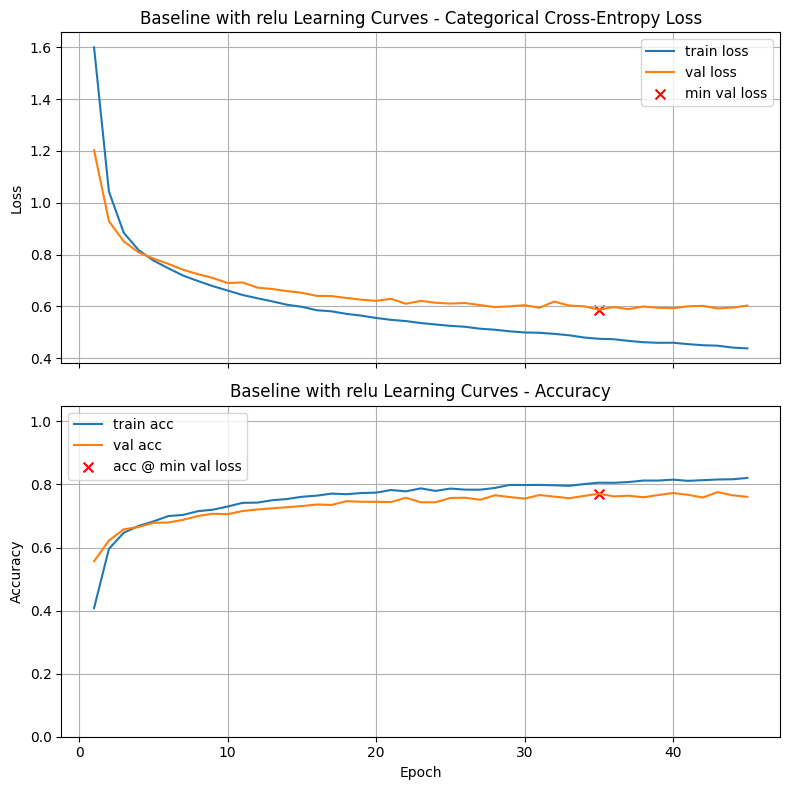

Final Training Loss:            0.4376
Final Training Accuracy:        0.8207
Final Validation Loss:          0.6031
Final Validation Accuracy:      0.7607
Minimum Validation Loss:        0.5870 (Epoch 35)
Validation Accuracy @ Min Loss: 0.7707

Test Loss: 0.6170
Test Accuracy: 0.7507

Validation-Test Gap (accuracy): 0.010000

Execution Time: 00:00:10

Baseline with sigmoid Learning Curves



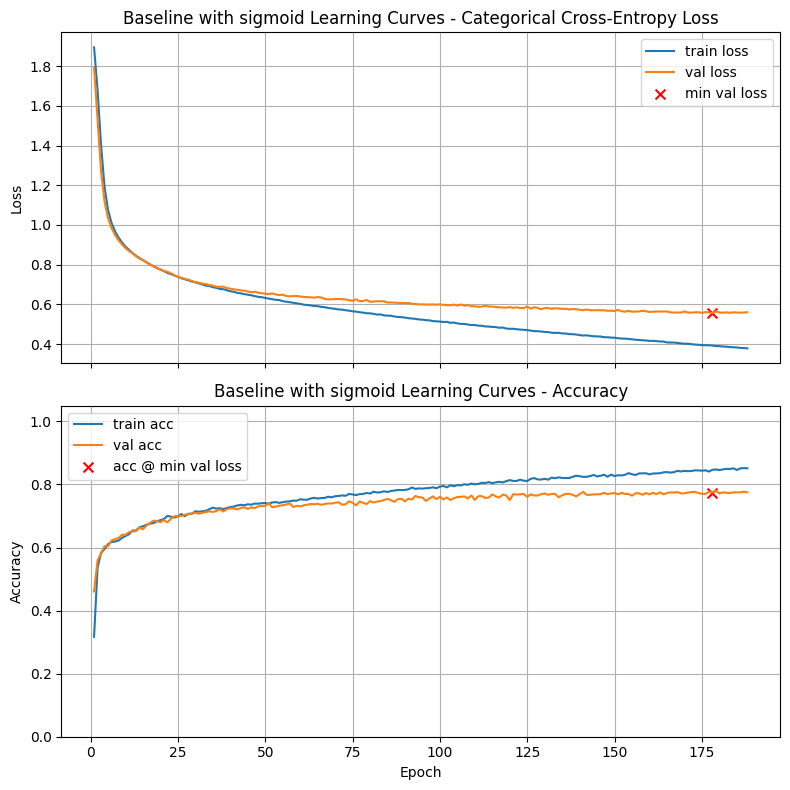

Final Training Loss:            0.3780
Final Training Accuracy:        0.8512
Final Validation Loss:          0.5599
Final Validation Accuracy:      0.7750
Minimum Validation Loss:        0.5560 (Epoch 178)
Validation Accuracy @ Min Loss: 0.7743

Test Loss: 0.5609
Test Accuracy: 0.7686

Validation-Test Gap (accuracy): 0.006429

Execution Time: 00:00:40

Baseline with tanh Learning Curves



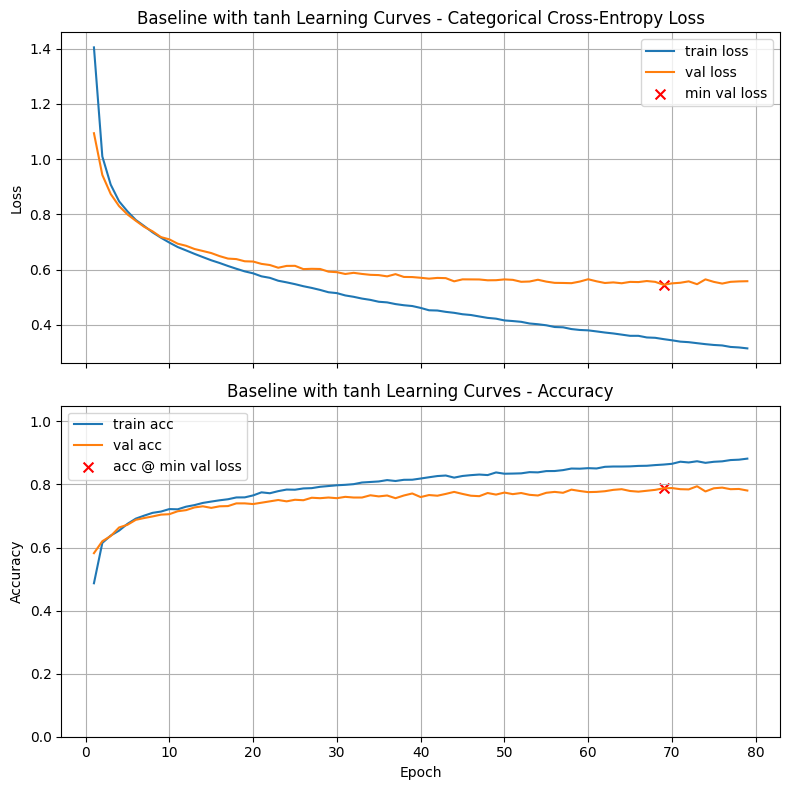

Final Training Loss:            0.3152
Final Training Accuracy:        0.8819
Final Validation Loss:          0.5582
Final Validation Accuracy:      0.7807
Minimum Validation Loss:        0.5452 (Epoch 69)
Validation Accuracy @ Min Loss: 0.7879

Test Loss: 0.5773
Test Accuracy: 0.7629

Validation-Test Gap (accuracy): 0.017857

Execution Time: 00:00:23


In [12]:
# Your code here. Add as many cells as you need. 
for act in ['relu', 'sigmoid', 'tanh']:
    model_baseline = build_model(X_train.shape[1], [ (64,act,0.0,0.0), (32,act,0.0,0.0)], n_classes)
    train_and_test(model_baseline, title="Baseline with " + act + " Learning Curves")

### Graded Questions

In [14]:
# Set a1a to the activation function which provided the best validation accuracy at the epoch of minimum validation loss

a1a = 2             # Replace with integer 0 (relu), 1 (sigmoid), or 2 (tanh)

In [15]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a1a = {a1a}') 


a1a = 2


In [16]:
# Set a1b to the validation accuracy found by this best activation function

a1b = 0.7879             # Replace 0.0 with your answer

In [17]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a1b = {a1b:.4f}') 

a1b = 0.7879


### Problem Two: Finding the Right Learning Rate

In this problem, you will continue working with the **baseline model** and determine which learning rate produces the best performance. As before, the model you evaluate should be the one saved by **early stopping** — the epoch where validation loss is minimized.

**Steps to follow:**

* Build and train the **baseline model** using the **activation function identified in Problem One**.

* Train and evaluate this model using each of the following learning rates:

  ```
      [1e-3, 5e-4, 1e-4, 5e-5, 1e-5]
  ```

* Identify which learning rate produces the **best validation accuracy** at the epoch of **minimum validation loss**, within a maximum of **500 epochs**.

* Answer the graded questions.


**Note: Smaller learning rates will generally take more epochs to reach the optimal point, so some of these will not engage early stopping, but run the full 500 epochs.**



Tanh with Learning Rate 0.001 Curves



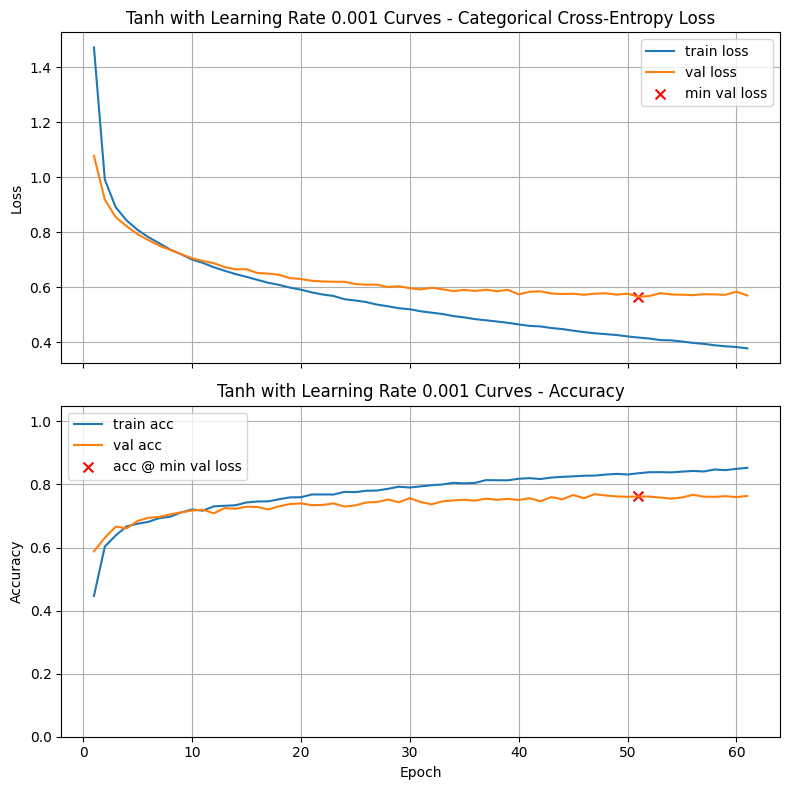

Final Training Loss:            0.3785
Final Training Accuracy:        0.8529
Final Validation Loss:          0.5705
Final Validation Accuracy:      0.7636
Minimum Validation Loss:        0.5657 (Epoch 51)
Validation Accuracy @ Min Loss: 0.7621

Test Loss: 0.5716
Test Accuracy: 0.7621

Validation-Test Gap (accuracy): 0.001429

Execution Time: 00:00:06

Tanh with Learning Rate 0.0005 Curves



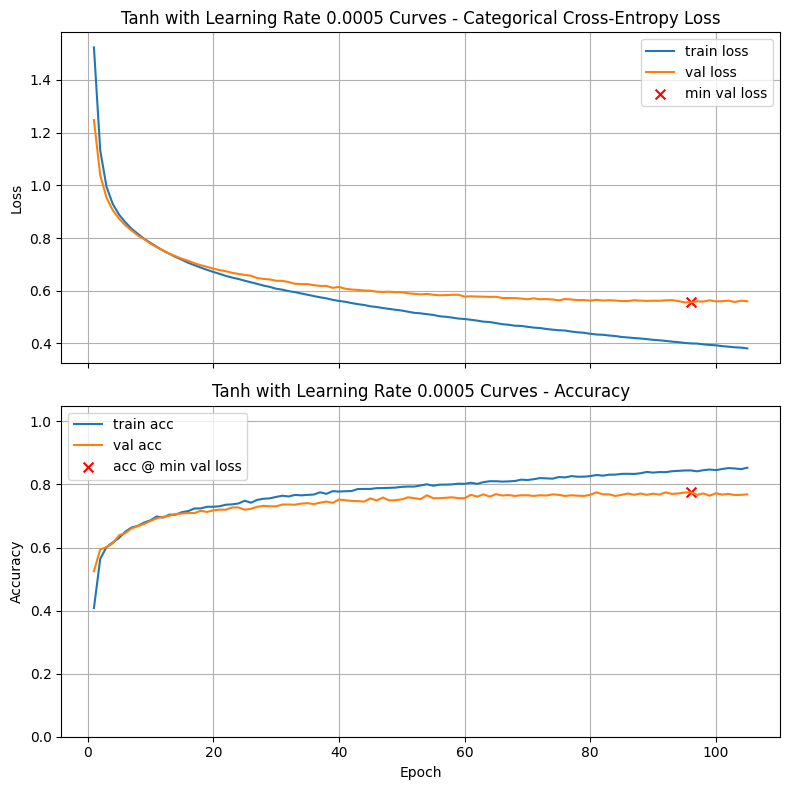

Final Training Loss:            0.3814
Final Training Accuracy:        0.8531
Final Validation Loss:          0.5604
Final Validation Accuracy:      0.7686
Minimum Validation Loss:        0.5560 (Epoch 96)
Validation Accuracy @ Min Loss: 0.7750

Test Loss: 0.5689
Test Accuracy: 0.7621

Validation-Test Gap (accuracy): 0.006429

Execution Time: 00:00:11

Tanh with Learning Rate 0.0001 Curves



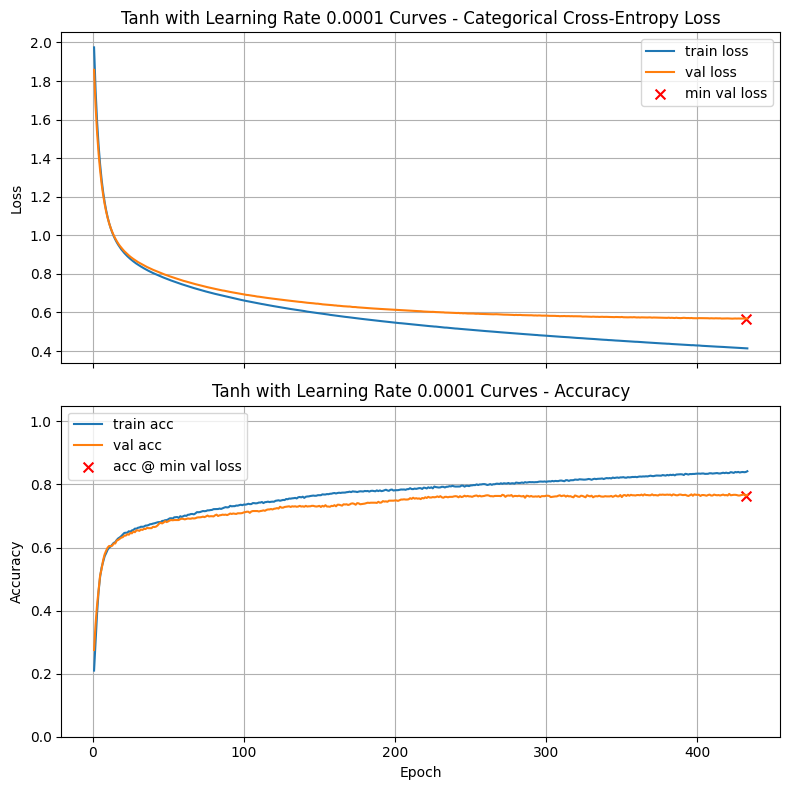

Final Training Loss:            0.4138
Final Training Accuracy:        0.8419
Final Validation Loss:          0.5687
Final Validation Accuracy:      0.7671
Minimum Validation Loss:        0.5680 (Epoch 432)
Validation Accuracy @ Min Loss: 0.7643

Test Loss: 0.5821
Test Accuracy: 0.7564

Validation-Test Gap (accuracy): 0.010714

Execution Time: 00:00:44

Tanh with Learning Rate 5e-05 Curves



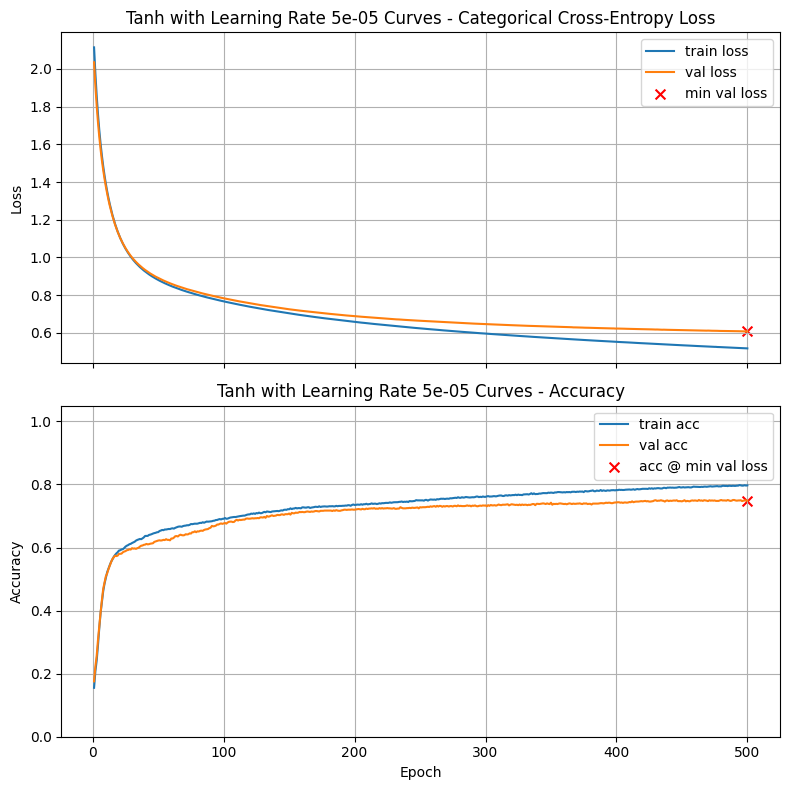

Final Training Loss:            0.5178
Final Training Accuracy:        0.7971
Final Validation Loss:          0.6078
Final Validation Accuracy:      0.7486
Minimum Validation Loss:        0.6078 (Epoch 500)
Validation Accuracy @ Min Loss: 0.7486

Test Loss: 0.6245
Test Accuracy: 0.7536

Validation-Test Gap (accuracy): 0.577857

Execution Time: 00:01:18

Tanh with Learning Rate 1e-05 Curves



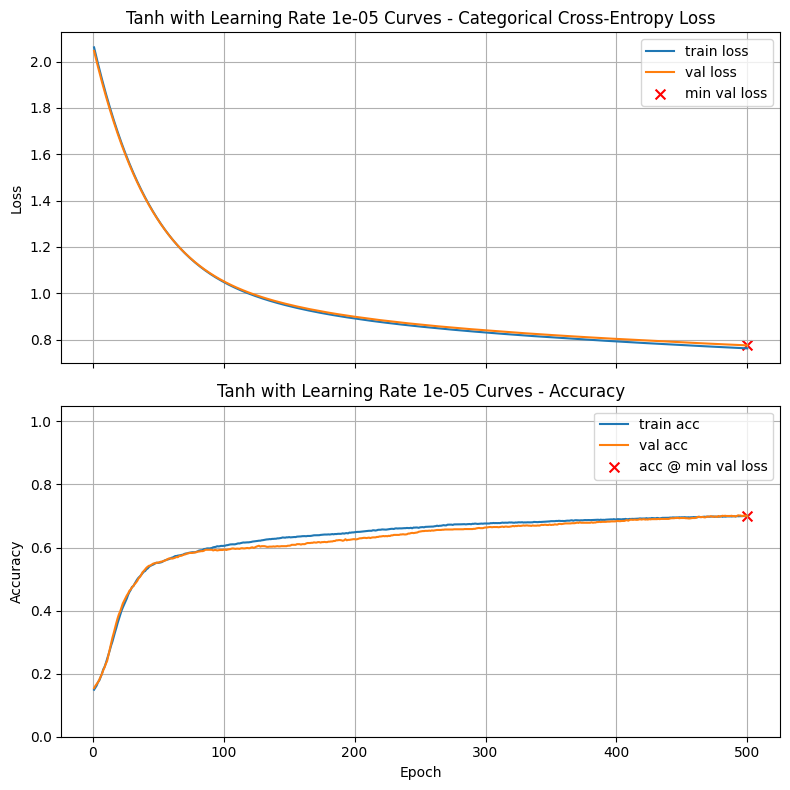

Final Training Loss:            0.7622
Final Training Accuracy:        0.7002
Final Validation Loss:          0.7752
Final Validation Accuracy:      0.6993
Minimum Validation Loss:        0.7752 (Epoch 500)
Validation Accuracy @ Min Loss: 0.6993

Test Loss: 0.7937
Test Accuracy: 0.6921

Validation-Test Gap (accuracy): 0.537857

Execution Time: 00:01:43


In [24]:
# Your code here. Add as many cells as you need. 
for lr in [1e-3, 5e-4, 1e-4, 5e-5, 1e-5]:
    model_lr = build_model(X_train.shape[1], [ (64,'tanh',0.0,0.0), (32,'tanh',0.0,0.0)], n_classes)
    train_and_test(model_lr, title="Tanh with Learning Rate " + str(lr) + " Curves", lr_schedule=lr)

#### Graded Questions

In [25]:
# Set a2a to the learning rate which provided the best validation accuracy at the epoch of minimum validation loss

a2a = 0.0005           # Replace 0.0 with your answer

In [26]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a2a = {a2a:.6f}') 

a2a = 0.000500


In [27]:
# Set a2b to the validation accuracy found by this best learning rate

a2b = 0.7750             # Replace 0.0 with your answer

In [28]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a2b = {a2b:.4f}') 

a2b = 0.7750


### Problem Three: Dropout

In this problem, you will explore how **dropout** can help prevent overfitting in neural networks. There are no absolute rules, but some useful heuristics are:

* Dropout typically works best in **later dense layers** (e.g., the second hidden layer of width 32) in the range **0.3–0.5**.
* If applied to **earlier layers** (e.g., the first hidden layer), dropout should be smaller, typically **0.0–0.2** (where 0.0 means no dropout).

**Steps to follow:**

* Build and train the **baseline model** using the **activation function from Problem One** and the **learning rate from Problem Two**.
* Investigate dropout in the ranges suggested, using increments of **0.1**.
* Identify which dropout configuration produces the **best validation accuracy** at the epoch of **minimum validation loss**.
* Answer the graded questions.



Dropout 0.0 -> 0.3 Curves



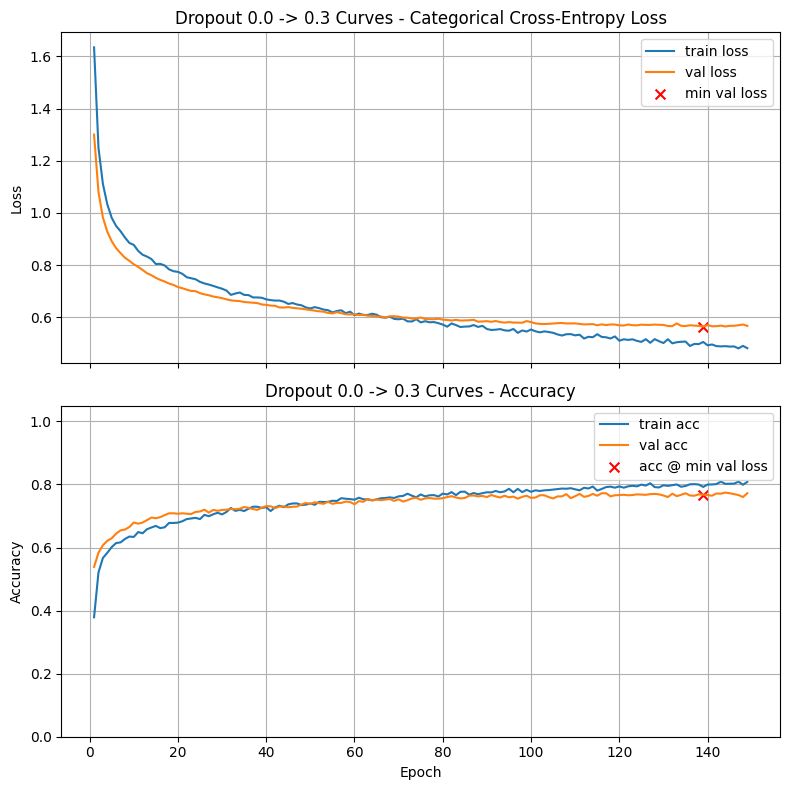

Final Training Loss:            0.4819
Final Training Accuracy:        0.8083
Final Validation Loss:          0.5677
Final Validation Accuracy:      0.7721
Minimum Validation Loss:        0.5651 (Epoch 139)
Validation Accuracy @ Min Loss: 0.7679

Test Loss: 0.6045
Test Accuracy: 0.7700

Validation-Test Gap (accuracy): 0.002143

Execution Time: 00:00:18

Dropout 0.0 -> 0.4 Curves



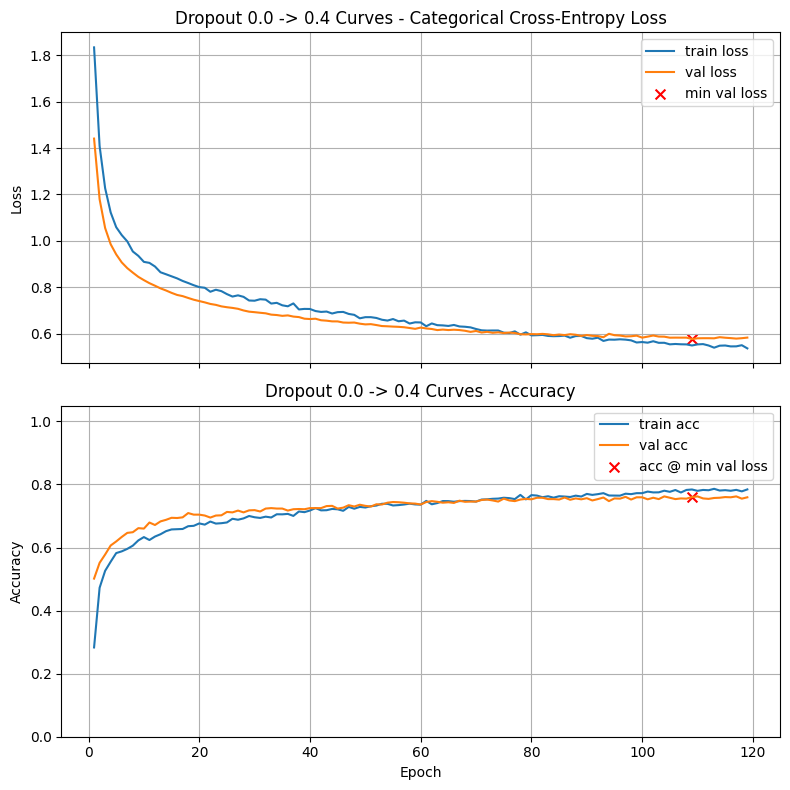

Final Training Loss:            0.5364
Final Training Accuracy:        0.7843
Final Validation Loss:          0.5829
Final Validation Accuracy:      0.7593
Minimum Validation Loss:        0.5768 (Epoch 109)
Validation Accuracy @ Min Loss: 0.7600

Test Loss: 0.6077
Test Accuracy: 0.7543

Validation-Test Gap (accuracy): 0.005000

Execution Time: 00:00:14

Dropout 0.0 -> 0.5 Curves



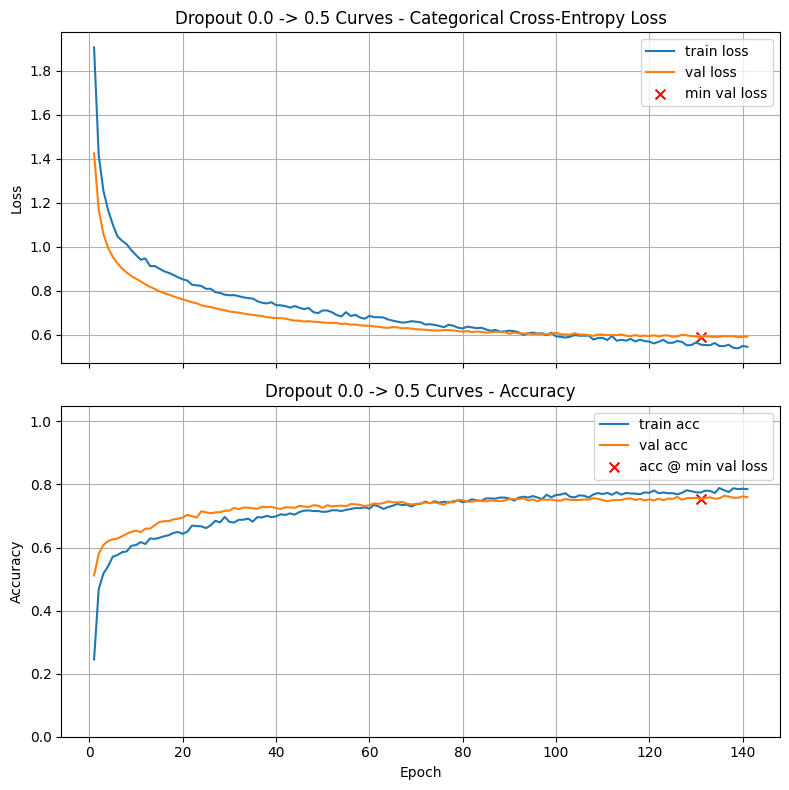

Final Training Loss:            0.5464
Final Training Accuracy:        0.7852
Final Validation Loss:          0.5926
Final Validation Accuracy:      0.7600
Minimum Validation Loss:        0.5893 (Epoch 131)
Validation Accuracy @ Min Loss: 0.7543

Test Loss: 0.6174
Test Accuracy: 0.7557

Validation-Test Gap (accuracy): 0.004286

Execution Time: 00:00:16

Dropout 0.1 -> 0.3 Curves



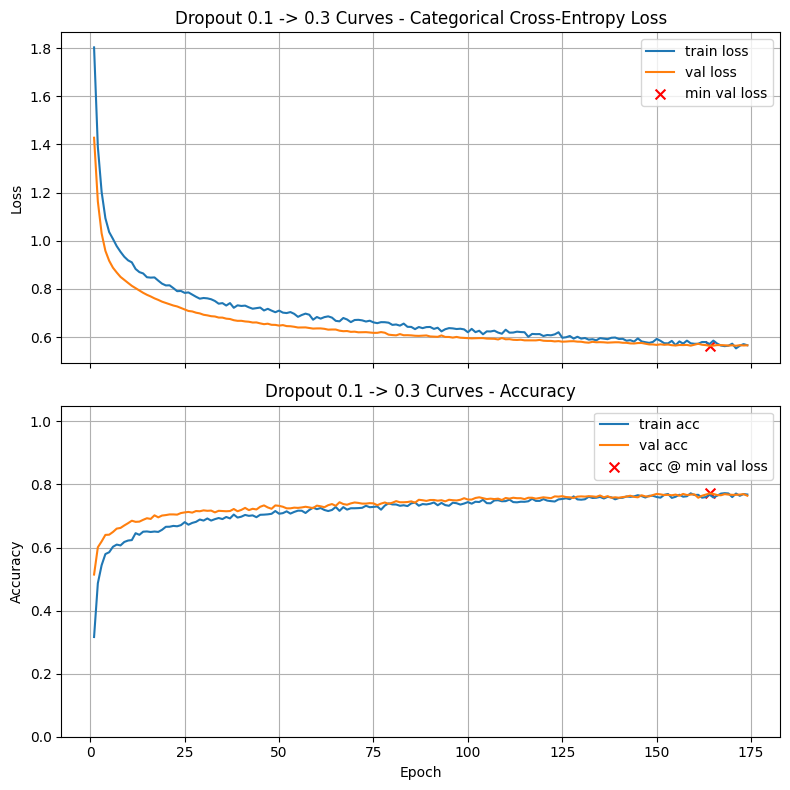

Final Training Loss:            0.5663
Final Training Accuracy:        0.7681
Final Validation Loss:          0.5661
Final Validation Accuracy:      0.7643
Minimum Validation Loss:        0.5641 (Epoch 164)
Validation Accuracy @ Min Loss: 0.7714

Test Loss: 0.5939
Test Accuracy: 0.7543

Validation-Test Gap (accuracy): 0.010000

Execution Time: 00:00:22

Dropout 0.1 -> 0.4 Curves



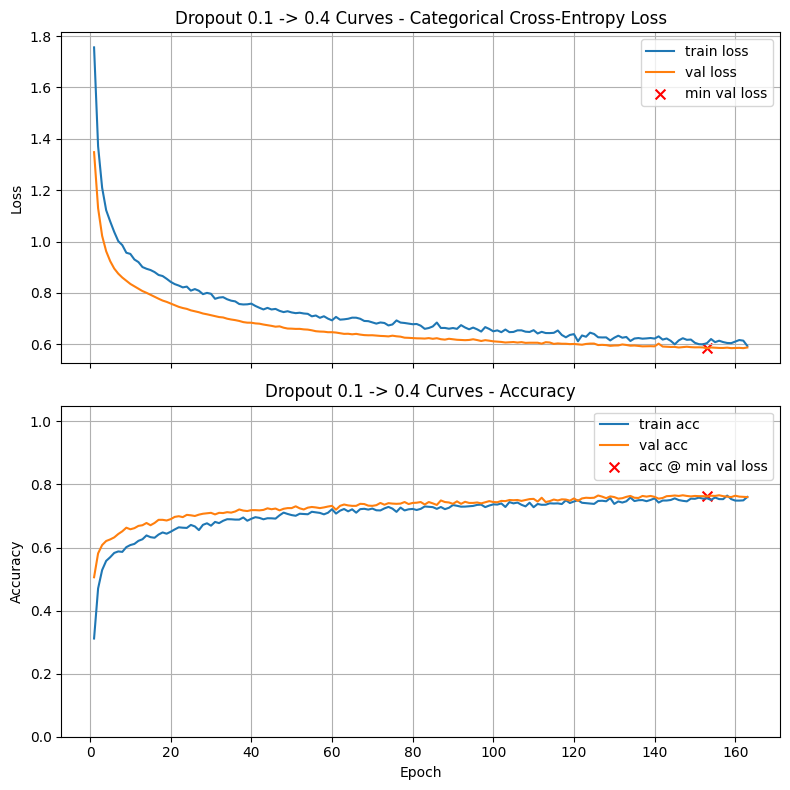

Final Training Loss:            0.5934
Final Training Accuracy:        0.7605
Final Validation Loss:          0.5876
Final Validation Accuracy:      0.7600
Minimum Validation Loss:        0.5841 (Epoch 153)
Validation Accuracy @ Min Loss: 0.7621

Test Loss: 0.6154
Test Accuracy: 0.7486

Validation-Test Gap (accuracy): 0.011429

Execution Time: 00:00:21

Dropout 0.1 -> 0.5 Curves



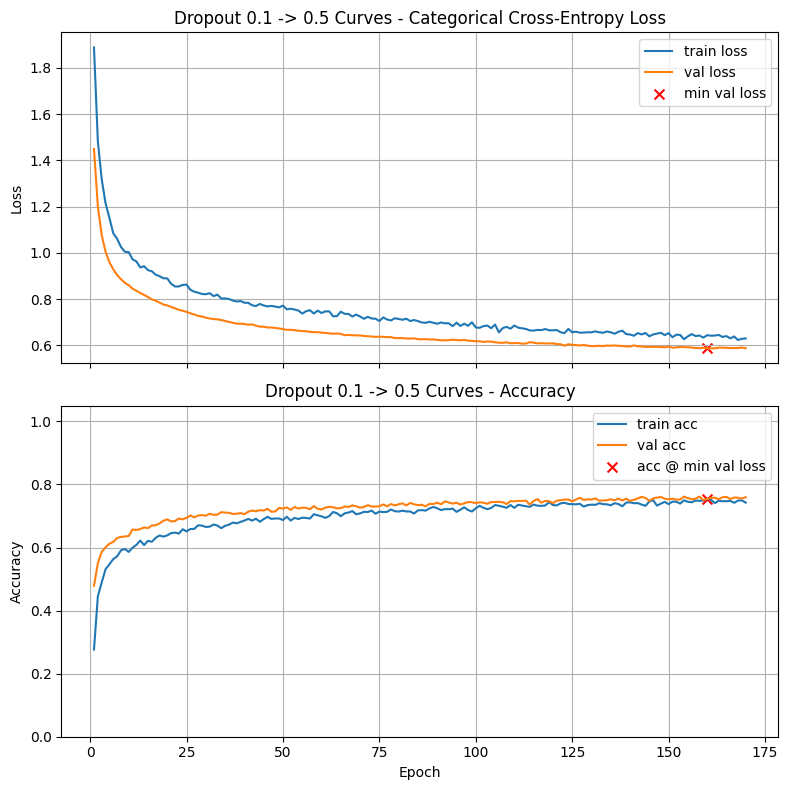

Final Training Loss:            0.6300
Final Training Accuracy:        0.7424
Final Validation Loss:          0.5875
Final Validation Accuracy:      0.7593
Minimum Validation Loss:        0.5871 (Epoch 160)
Validation Accuracy @ Min Loss: 0.7543

Test Loss: 0.6243
Test Accuracy: 0.7429

Validation-Test Gap (accuracy): 0.016429

Execution Time: 00:00:22

Dropout 0.2 -> 0.3 Curves



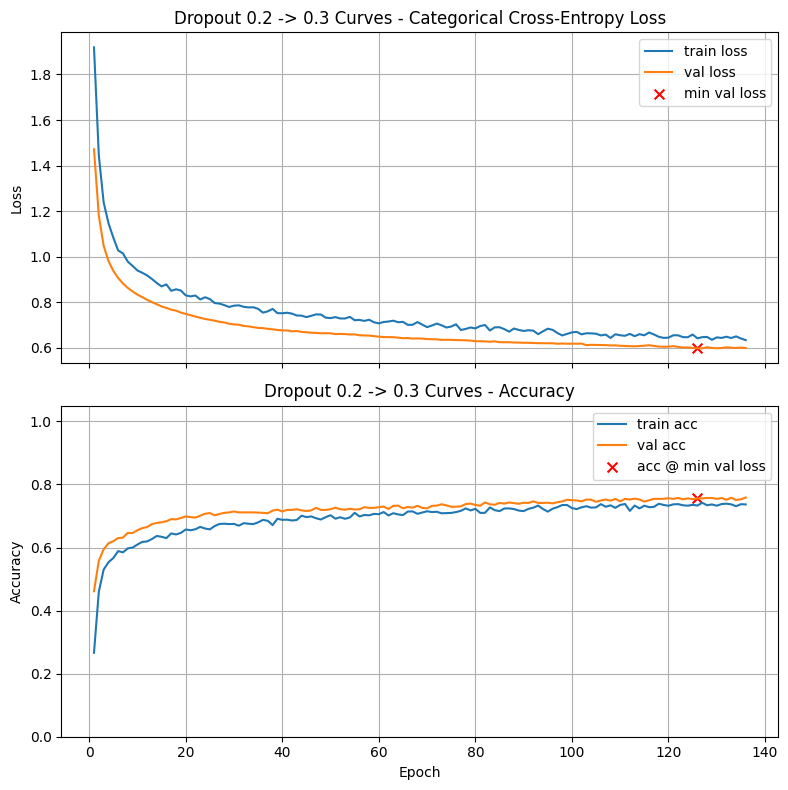

Final Training Loss:            0.6342
Final Training Accuracy:        0.7367
Final Validation Loss:          0.5996
Final Validation Accuracy:      0.7586
Minimum Validation Loss:        0.5979 (Epoch 126)
Validation Accuracy @ Min Loss: 0.7557

Test Loss: 0.6319
Test Accuracy: 0.7329

Validation-Test Gap (accuracy): 0.025714

Execution Time: 00:00:17

Dropout 0.2 -> 0.4 Curves



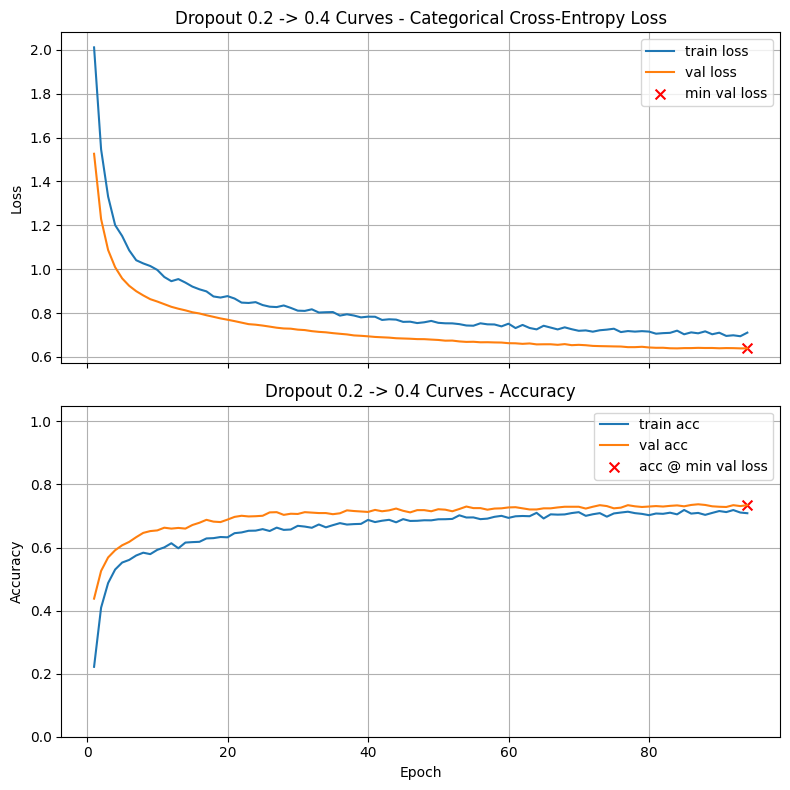

Final Training Loss:            0.7104
Final Training Accuracy:        0.7088
Final Validation Loss:          0.6387
Final Validation Accuracy:      0.7343
Minimum Validation Loss:        0.6387 (Epoch 94)
Validation Accuracy @ Min Loss: 0.7343

Test Loss: 0.6650
Test Accuracy: 0.7243

Validation-Test Gap (accuracy): 0.010000

Execution Time: 00:00:12

Dropout 0.2 -> 0.5 Curves



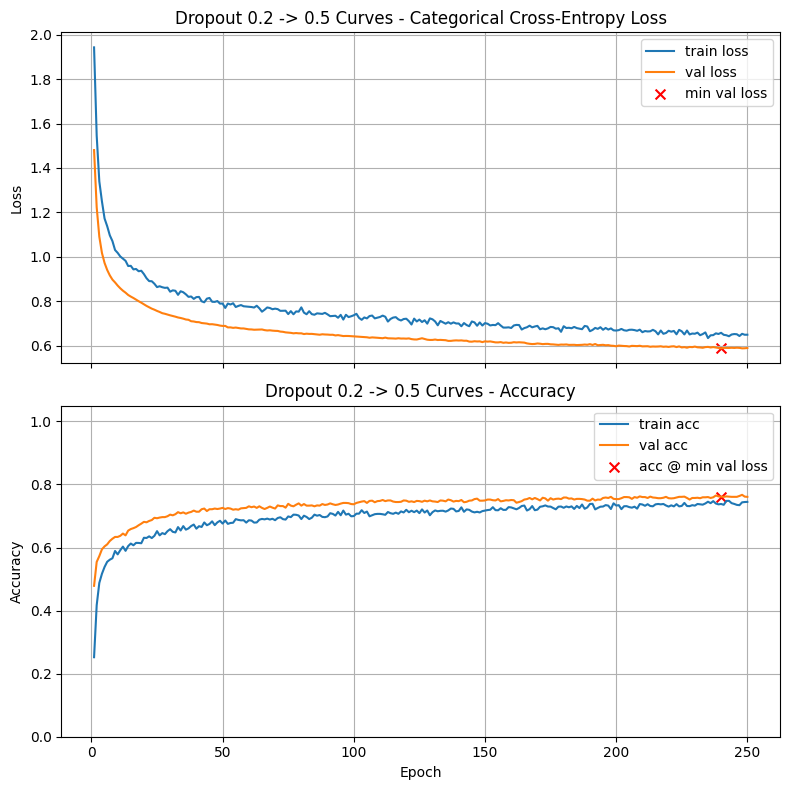

Final Training Loss:            0.6490
Final Training Accuracy:        0.7448
Final Validation Loss:          0.5892
Final Validation Accuracy:      0.7607
Minimum Validation Loss:        0.5875 (Epoch 240)
Validation Accuracy @ Min Loss: 0.7614

Test Loss: 0.6281
Test Accuracy: 0.7429

Validation-Test Gap (accuracy): 0.017857

Execution Time: 00:00:32


In [35]:
# Your code here. Add as many cells as you need. 
for earlydropout in np.arange(0, 0.3, 0.1):
    for laterdropout in np.arange(0.3, 0.6, 0.1):
        model_dr = build_model(X_train.shape[1], [ (64,'tanh',0.0,earlydropout), (32,'tanh',0.0,laterdropout)], n_classes)
        train_and_test(model_dr, title="Dropout " + str(earlydropout) + " -> " + str(laterdropout) + " Curves", lr_schedule=0.0005)

In [36]:
# Set a3a to the pair (dropout_rate_64,dropout_rate_32) of dropout rates for the two hidden layers which provided the best 
# validation accuracy at the epoch of minimum validation loss

a3a = (0.1,0.3)             # Replace (0.0,0.0) with your answer

In [37]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a3a = {a3a}') 

a3a = (0.1, 0.3)


In [38]:
# Set a3b to the validation accuracy found by this best pair of dropout rates

a3b = 0.7714             # Replace 0.0 with your answer

In [39]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a3b = {a3b:.4f}') 

a3b = 0.7714


### Problem Four: L2 Regularization

In this problem, you will explore how **L2 regularization** (also called *weight decay*) can help prevent overfitting in neural networks. There are no absolute rules, but some useful heuristics are:

* Start simply by using the **same λ in both hidden layers**, with values:

  ```
      1e-4, 1e-3, 1e-2
  ```

* If validation results suggest underfitting in the first layer or persistent overfitting in the later one, then try adjusting per layer, for example:

  * First hidden layer: λ = 1e-4
  * Second hidden layer: λ = 1e-3

**Steps to follow:**

* Build and train the **baseline model** using the **activation function from Problem One** and the **learning rate from Problem Two**, but **without dropout**.
* Investigate at least the four cases suggested (three with the same λ and one with different λ values). You may also consider additional combinations.
* Identify which configuration produces the **best validation accuracy** at the epoch of **minimum validation loss**.
* Answer the graded questions.



L2 of 0.0001 Learning Curves



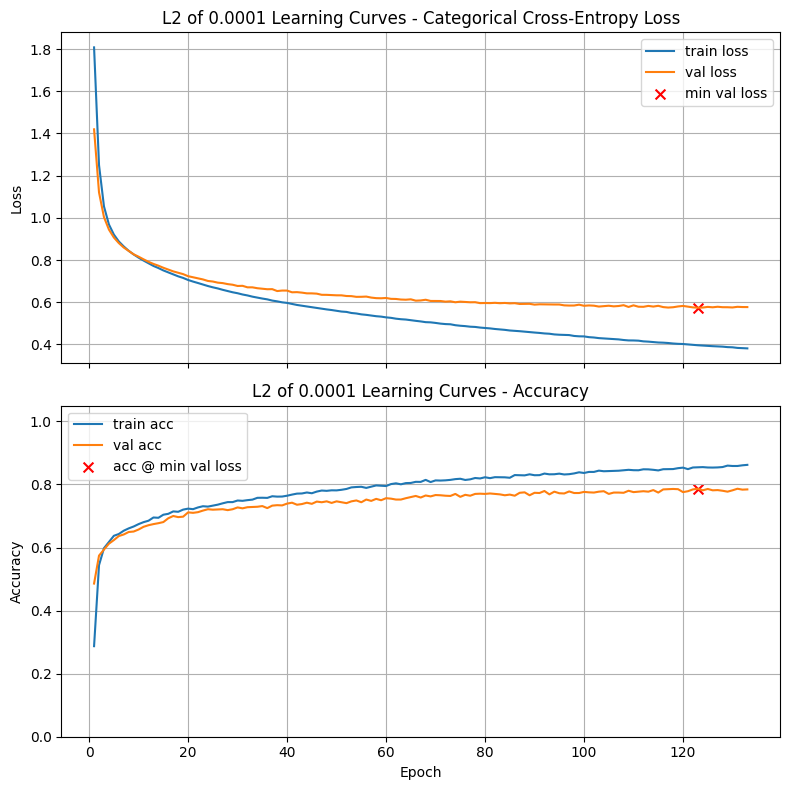

Final Training Loss:            0.3812
Final Training Accuracy:        0.8621
Final Validation Loss:          0.5770
Final Validation Accuracy:      0.7843
Minimum Validation Loss:        0.5742 (Epoch 123)
Validation Accuracy @ Min Loss: 0.7864

Test Loss: 0.5697
Test Accuracy: 0.7736

Validation-Test Gap (accuracy): 0.010714

Execution Time: 00:00:15

L2 of 0.001 Learning Curves



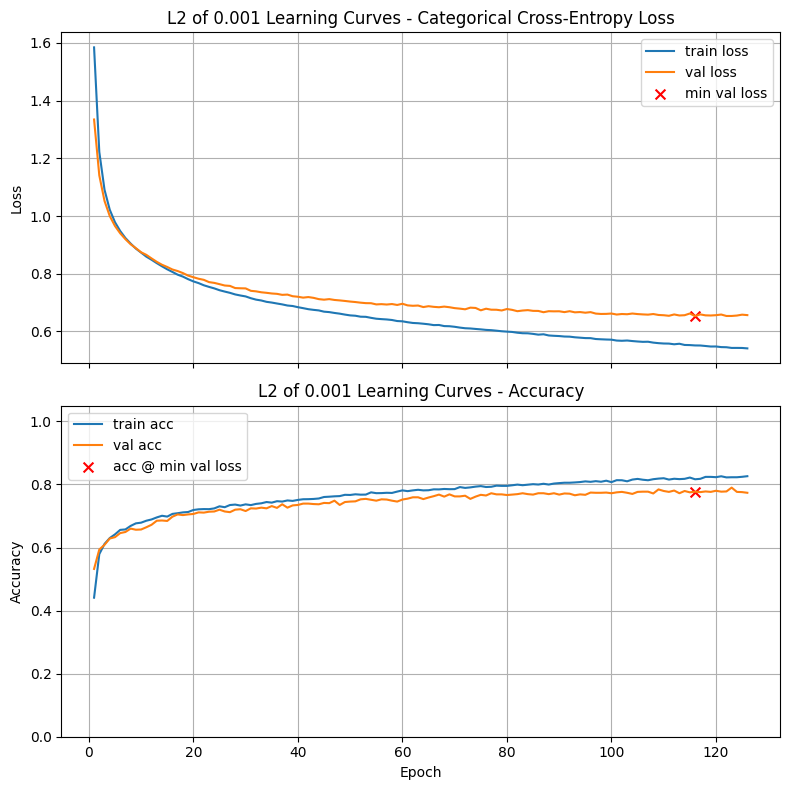

Final Training Loss:            0.5414
Final Training Accuracy:        0.8262
Final Validation Loss:          0.6566
Final Validation Accuracy:      0.7736
Minimum Validation Loss:        0.6533 (Epoch 116)
Validation Accuracy @ Min Loss: 0.7771

Test Loss: 0.6711
Test Accuracy: 0.7671

Validation-Test Gap (accuracy): 0.006429

Execution Time: 00:00:15

L2 of 0.01 Learning Curves



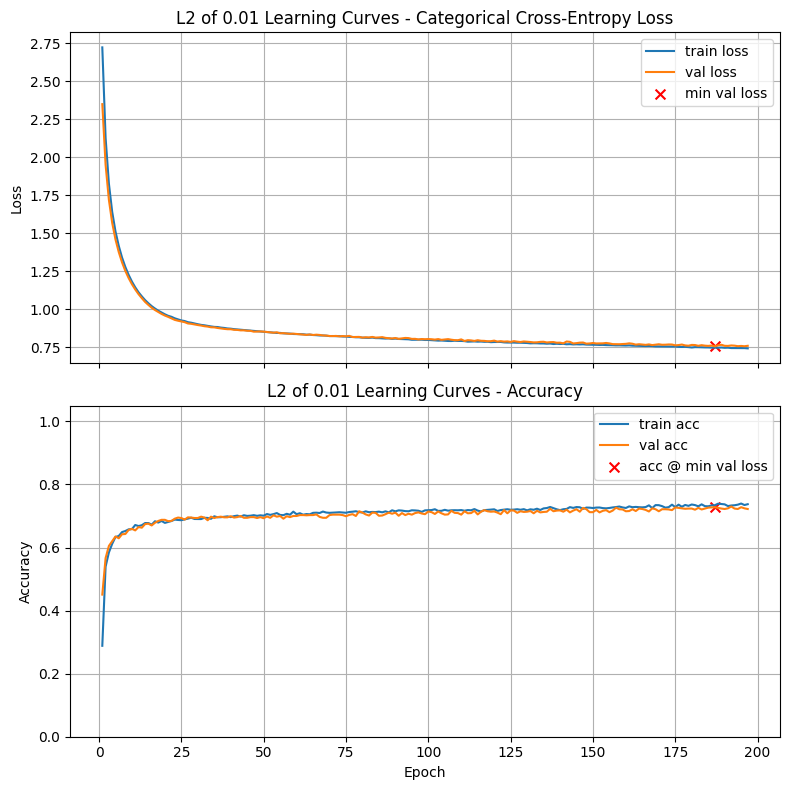

Final Training Loss:            0.7416
Final Training Accuracy:        0.7374
Final Validation Loss:          0.7585
Final Validation Accuracy:      0.7221
Minimum Validation Loss:        0.7551 (Epoch 187)
Validation Accuracy @ Min Loss: 0.7279

Test Loss: 0.7864
Test Accuracy: 0.7257

Validation-Test Gap (accuracy): 0.003571

Execution Time: 00:00:24


In [41]:
# Your code here. Add as many cells as you need. 
for l2 in [1e-4, 1e-3, 1e-2]:
# l2 = 1e-3
    model_l2 = build_model(X_train.shape[1], [ (64,'tanh',l2,0), (32,'tanh',l2,0)], n_classes)
    train_and_test(model_l2, title="L2 of " + str(l2) + " Learning Curves", lr_schedule=0.0005)


L2 of 0.01 Learning Curves



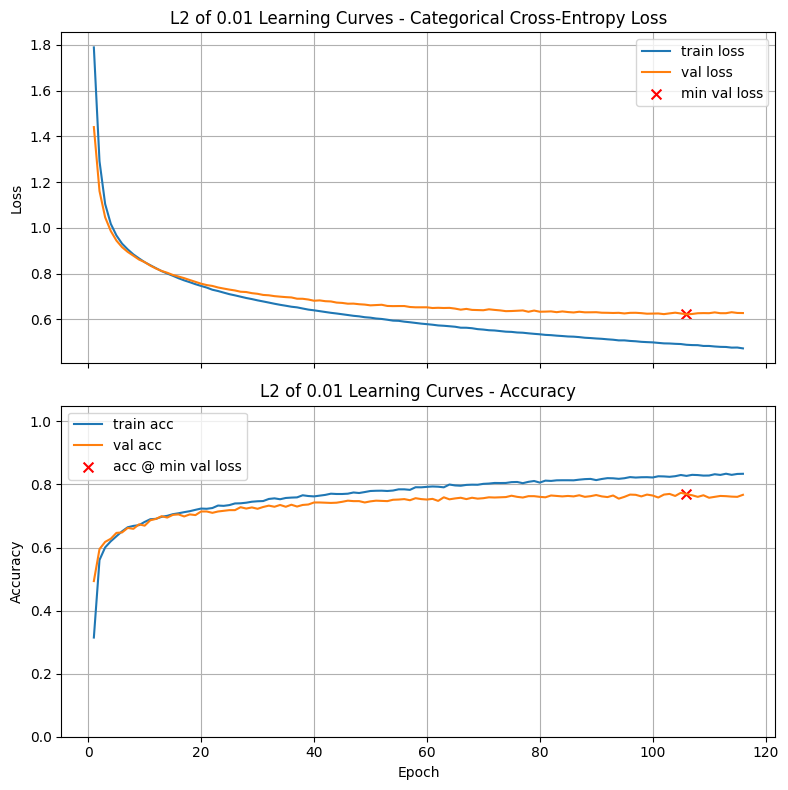

Final Training Loss:            0.4733
Final Training Accuracy:        0.8338
Final Validation Loss:          0.6278
Final Validation Accuracy:      0.7671
Minimum Validation Loss:        0.6222 (Epoch 106)
Validation Accuracy @ Min Loss: 0.7693

Test Loss: 0.6308
Test Accuracy: 0.7443

Validation-Test Gap (accuracy): 0.022857

Execution Time: 00:00:13


In [42]:
model_l2 = build_model(X_train.shape[1], [ (64,'tanh',1e-4,0), (32,'tanh',1e-3,0)], n_classes)
train_and_test(model_l2, title="L2 of " + str(l2) + " Learning Curves", lr_schedule=0.0005)

In [43]:
# Set a4a to the pair (L2_lambda_64,L2_lambda_32) of the L2 lambdas for the two hidden layers which provided the best 
# validation accuracy at the epoch of minimum validation loss

a4a = (1e-4,1e-4)             # Replace (0.0,0.0) with your answer

In [44]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a4a = {a4a}') 

a4a = (0.0001, 0.0001)


In [45]:
# Set a4b to the validation accuracy found by this best pair of lambdas

a4b = 0.7864             # Replace 0.0 with your answer

In [46]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a4b = {a4b:.4f}') 

a4b = 0.7864


### Problem Five: Combining Dropout with L2 Regularization

In this problem, you will explore how **dropout** and **L2 regularization** can work together to prevent overfitting. These two methods complement each other, but must be balanced carefully. A useful rule of thumb is:

* If dropout is **high**, use a **smaller λ**.
* If dropout is **low**, you can afford a **larger λ**.

**Steps to follow:**

* Build and train the **baseline model** using the **activation function from Problem One** and the **learning rate from Problem Two**.
* Investigate combinations of dropout and L2:

  * First, use the **dropout rate you identified in Problem Three** as a baseline.
  * Then, add L2 to both hidden layers with values:

    ```
        1e-4, 1e-3, 1e-2
    ```

    while keeping dropout fixed.
  * Finally, try **reducing dropout slightly** when L2 is added to see if performance improves.
  * [Optional] You may wish to investigate other combinations not covered here; for example, promising but not optimal choices of dropout rates may provide overall better performance when combines with L2 Regulari 
* Identify which combination produces the **best validation accuracy** at the epoch of **minimum validation loss**.
* Answer the graded questions.




L2 of 0.0001 with dropout, Learning Curves



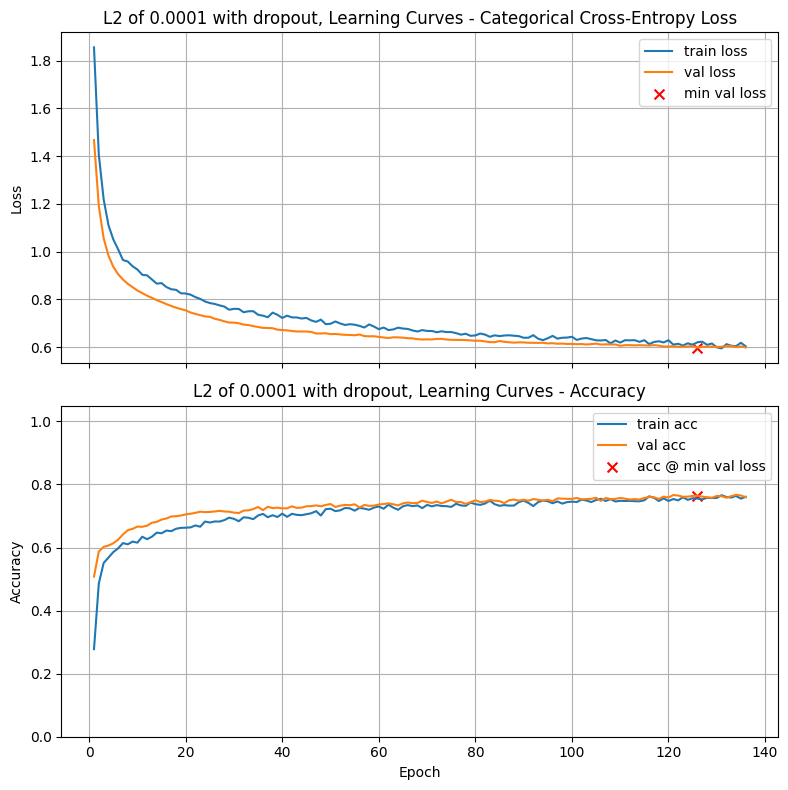

Final Training Loss:            0.6034
Final Training Accuracy:        0.7610
Final Validation Loss:          0.5987
Final Validation Accuracy:      0.7593
Minimum Validation Loss:        0.5982 (Epoch 126)
Validation Accuracy @ Min Loss: 0.7643

Test Loss: 0.6255
Test Accuracy: 0.7436

Validation-Test Gap (accuracy): 0.015714

Execution Time: 00:00:20

L2 of 0.001 with dropout, Learning Curves



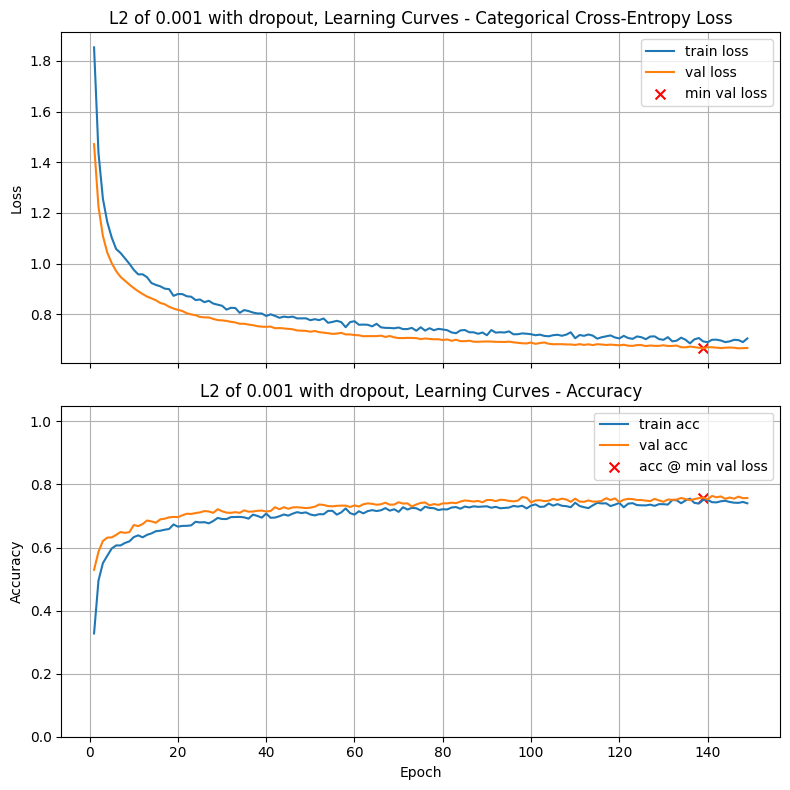

Final Training Loss:            0.7044
Final Training Accuracy:        0.7402
Final Validation Loss:          0.6669
Final Validation Accuracy:      0.7571
Minimum Validation Loss:        0.6653 (Epoch 139)
Validation Accuracy @ Min Loss: 0.7586

Test Loss: 0.7025
Test Accuracy: 0.7393

Validation-Test Gap (accuracy): 0.017857

Execution Time: 00:00:22

L2 of 0.01 with dropout, Learning Curves



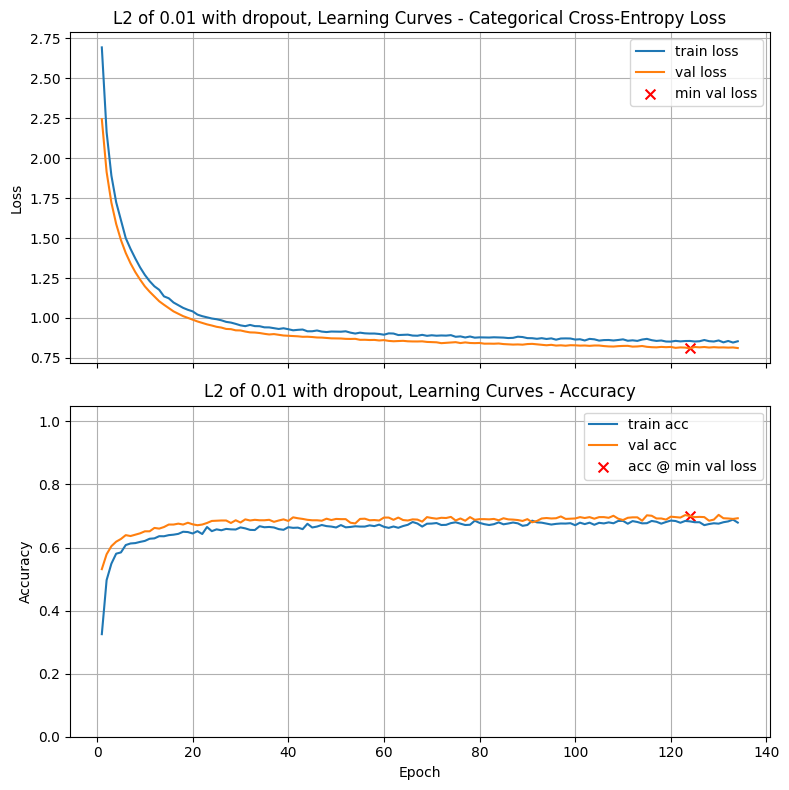

Final Training Loss:            0.8539
Final Training Accuracy:        0.6790
Final Validation Loss:          0.8115
Final Validation Accuracy:      0.6929
Minimum Validation Loss:        0.8093 (Epoch 124)
Validation Accuracy @ Min Loss: 0.7000

Test Loss: 0.8353
Test Accuracy: 0.6986

Validation-Test Gap (accuracy): 0.005714

Execution Time: 00:00:19


In [49]:
# Your code here. Add as many cells as you need.
for l2 in [1e-4, 1e-3, 1e-2]:
# l2 = 1e-3
    model_l2 = build_model(X_train.shape[1], [ (64,'tanh',l2,0.1), (32,'tanh',l2,0.3)], n_classes)
    train_and_test(model_l2, title="L2 of " + str(l2) + " with dropout, Learning Curves", lr_schedule=0.0005)


L2 of 0.0001 with dropout, Learning Curves



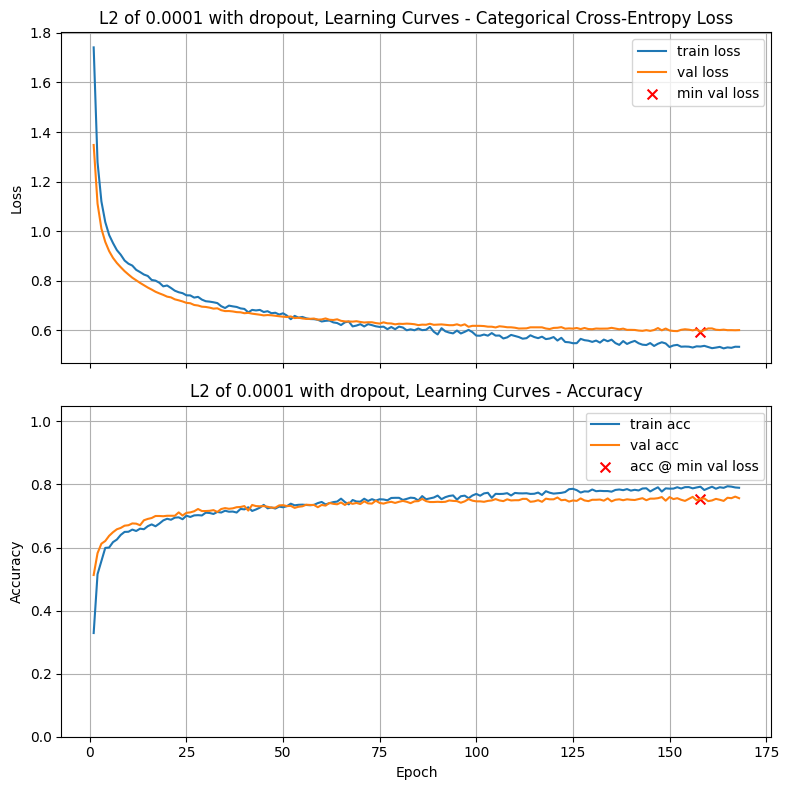

Final Training Loss:            0.5324
Final Training Accuracy:        0.7895
Final Validation Loss:          0.5998
Final Validation Accuracy:      0.7564
Minimum Validation Loss:        0.5936 (Epoch 158)
Validation Accuracy @ Min Loss: 0.7543

Test Loss: 0.6212
Test Accuracy: 0.7557

Validation-Test Gap (accuracy): 0.000714

Execution Time: 00:00:25

L2 of 0.001 with dropout, Learning Curves



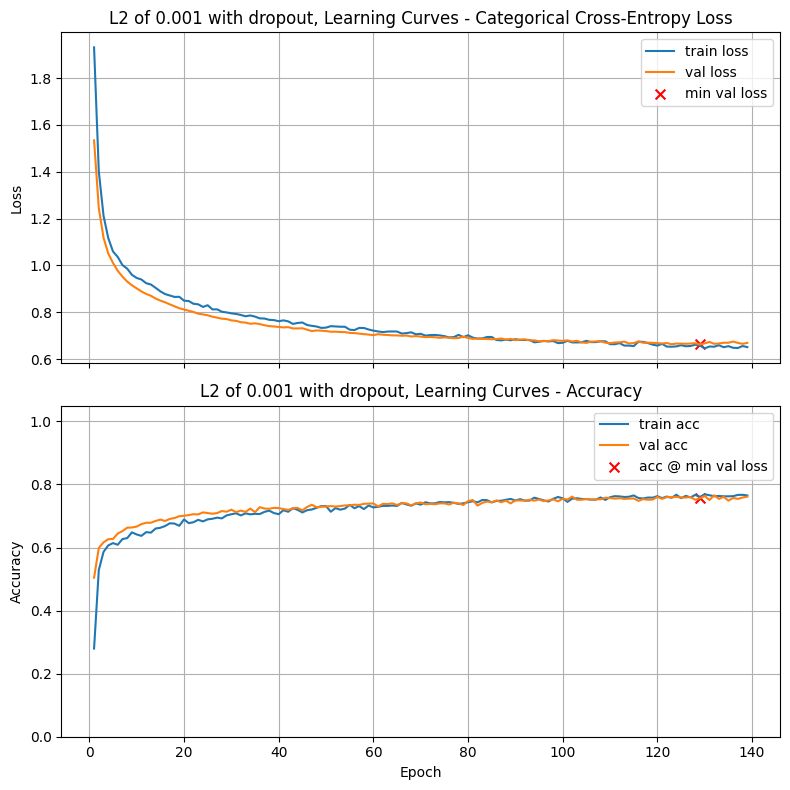

Final Training Loss:            0.6512
Final Training Accuracy:        0.7652
Final Validation Loss:          0.6693
Final Validation Accuracy:      0.7614
Minimum Validation Loss:        0.6626 (Epoch 129)
Validation Accuracy @ Min Loss: 0.7564

Test Loss: 0.6879
Test Accuracy: 0.7514

Validation-Test Gap (accuracy): 0.010000

Execution Time: 00:00:20

L2 of 0.01 with dropout, Learning Curves



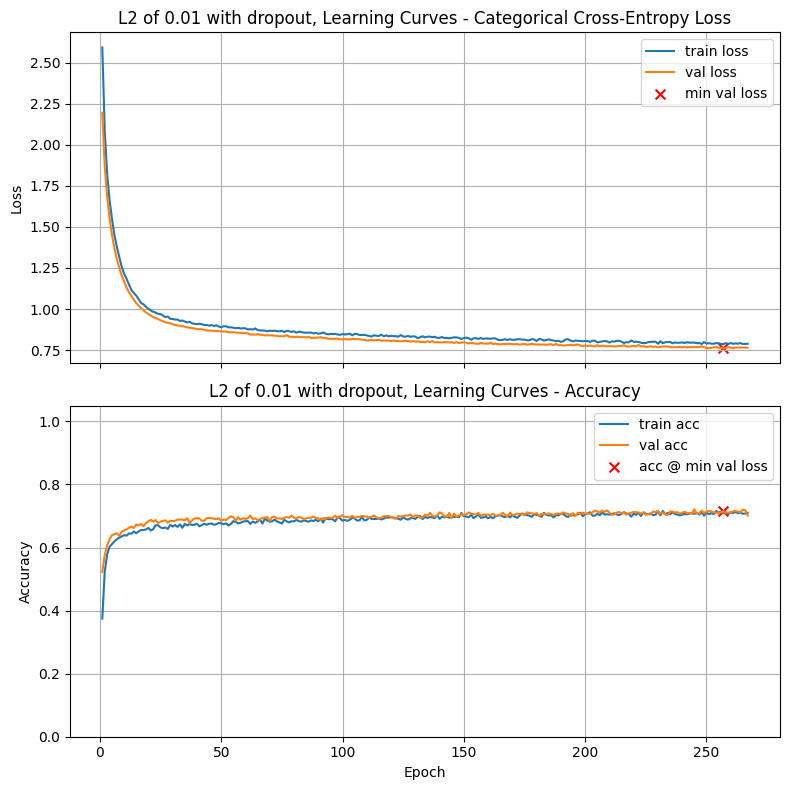

Final Training Loss:            0.7885
Final Training Accuracy:        0.7102
Final Validation Loss:          0.7641
Final Validation Accuracy:      0.7014
Minimum Validation Loss:        0.7603 (Epoch 257)
Validation Accuracy @ Min Loss: 0.7150

Test Loss: 0.7852
Test Accuracy: 0.7057

Validation-Test Gap (accuracy): 0.004286

Execution Time: 00:00:40


In [50]:
for l2 in [1e-4, 1e-3, 1e-2]:
    model_l2 = build_model(X_train.shape[1], [ (64,'tanh',l2,0.05), (32,'tanh',l2,0.2)], n_classes)
    train_and_test(model_l2, title="L2 of " + str(l2) + " with dropout, Learning Curves", lr_schedule=0.0005)

In [53]:
# Set a5 to the validation accuracy found by this best combination of dropout and L2 regularization

a5 = 0.7643             # Replace 0.0 with your answer

In [54]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a5 = {a5:.4f}') 

a5 = 0.7643


### Problem Six: Build and Train Your Best Model

In this final problem, you will design and train your **best-performing model** using the techniques explored in the previous problems. You may make your own choices for:

* **Model architecture** (number of layers, widths, etc.)
* **Learning rate**
* **Batch size** (a new hyperparameter not varied in earlier problems)
* **Dropout rates** in both layers
* **L2 λ values** in both layers
* **[Optional but strongly suggested]:** Learning rate scheduling, using either **Exponential Decay** or **Cosine Decay**.

  * For Exponential Decay, typical decay rates are **0.90–0.999**, with **0.95** often a good starting point.

**Steps to follow:**

* Build and train the model according to your design choices.
* Use early stopping as before to evaluate performance at the epoch of **minimum validation loss**.
* Answer the graded question.



L2 of 0.0001 Learning Curves



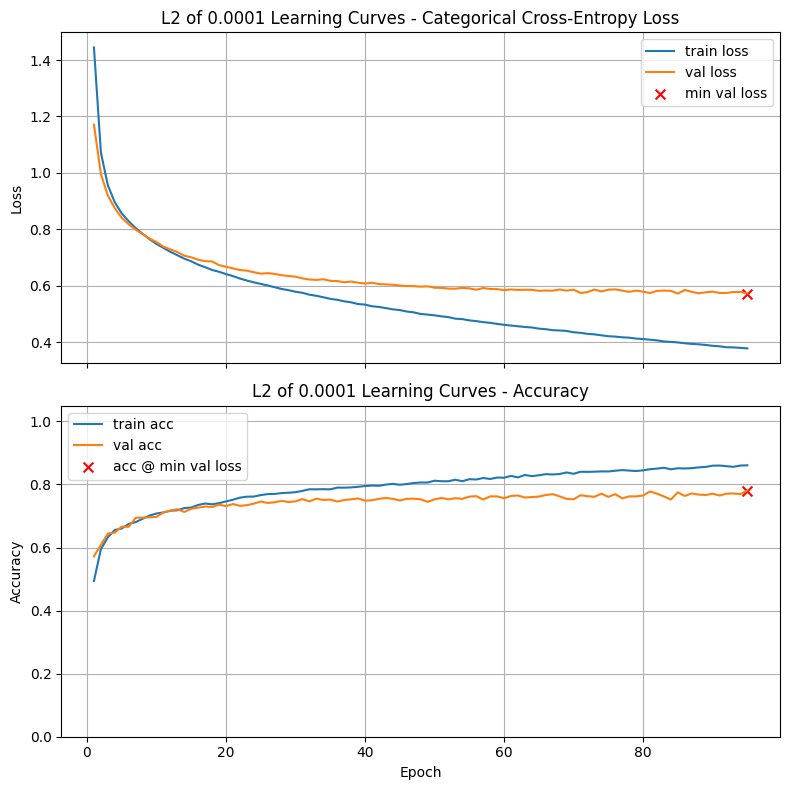

Final Training Loss:            0.3786
Final Training Accuracy:        0.8607
Final Validation Loss:          0.5728
Final Validation Accuracy:      0.7807
Minimum Validation Loss:        0.5728 (Epoch 95)
Validation Accuracy @ Min Loss: 0.7807

Test Loss: 0.5922
Test Accuracy: 0.7686

Validation-Test Gap (accuracy): 0.012143

Execution Time: 00:00:23

L2 of 0.001 Learning Curves



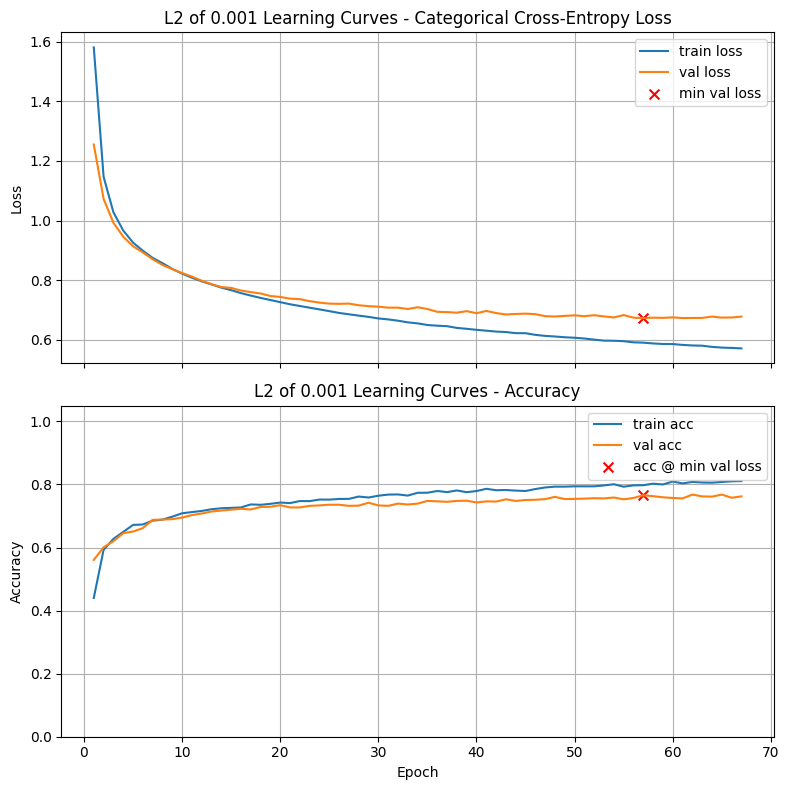

Final Training Loss:            0.5705
Final Training Accuracy:        0.8107
Final Validation Loss:          0.6772
Final Validation Accuracy:      0.7621
Minimum Validation Loss:        0.6722 (Epoch 57)
Validation Accuracy @ Min Loss: 0.7657

Test Loss: 0.6825
Test Accuracy: 0.7557

Validation-Test Gap (accuracy): 0.006429

Execution Time: 00:00:16

L2 of 0.01 Learning Curves



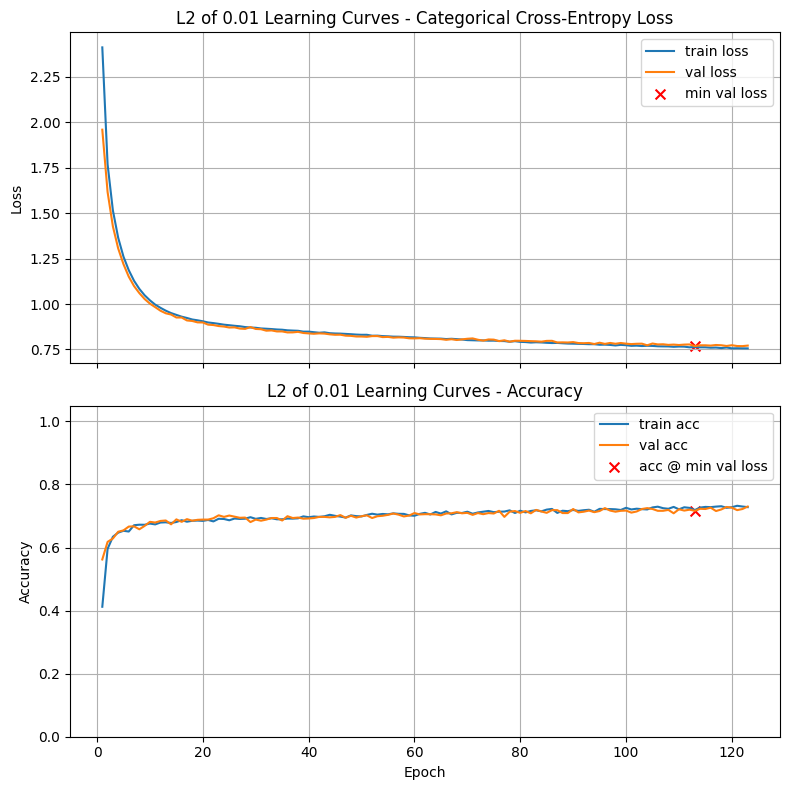

Final Training Loss:            0.7560
Final Training Accuracy:        0.7281
Final Validation Loss:          0.7713
Final Validation Accuracy:      0.7300
Minimum Validation Loss:        0.7684 (Epoch 113)
Validation Accuracy @ Min Loss: 0.7164

Test Loss: 0.7923
Test Accuracy: 0.7136

Validation-Test Gap (accuracy): 0.016429

Execution Time: 00:00:31


In [56]:
# Your code here
from tensorflow.python.keras.optimizer_v2.learning_rate_schedule import CosineDecay
batch_size = 32

for l2 in [1e-4, 1e-3, 1e-2]:
# l2 = 1e-3
    model_l2 = build_model(X_train.shape[1], [ (64,'tanh',l2,0), (32,'tanh',l2,0)], n_classes)
    train_and_test(model_l2, title="L2 of " + str(l2) + " Learning Curves", lr_schedule=0.0005, batch_size=batch_size)

In [57]:
# Set a6 to the validation accuracy found by this best model

a6 = 0.7807             # Replace 0.0 with your answer

In [58]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a6 = {a6:.4f}') 

a6 = 0.7807


### Optional: Print out your results of all experiments

In [59]:
print_results()

Baseline with tanh Learning Curves      	0.7879
L2 of 0.0001 Learning Curves            	0.7807
Tanh with Learning Rate 0.0005 Curves   	0.7750
Baseline with sigmoid Learning Curves   	0.7743
Dropout 0.1 -> 0.3 Curves               	0.7714
Baseline with relu Learning Curves      	0.7707
Dropout 0.0 -> 0.3 Curves               	0.7679
L2 of 0.001 Learning Curves             	0.7657
Tanh with Learning Rate 0.0001 Curves   	0.7643
Tanh with Learning Rate 0.001 Curves    	0.7621
Dropout 0.1 -> 0.4 Curves               	0.7621
Dropout 0.2 -> 0.5 Curves               	0.7614
Dropout 0.0 -> 0.4 Curves               	0.7600
L2 of 0.001 with dropout, Learning Curves	0.7564
Dropout 0.2 -> 0.3 Curves               	0.7557
Dropout 0.0 -> 0.6 Curves               	0.7543
Dropout 0.0 -> 0.5 Curves               	0.7543
Dropout 0.1 -> 0.5 Curves               	0.7543
L2 of 0.0001 with dropout, Learning Curves	0.7543
Tanh with Learning Rate 5e-05 Curves    	0.7486
Tanh with Learning Rate 0.1e-05 Curve

## Reflection Questions (ungraded)

It would be a great idea to think through your answers to these questions, then give ChatGPT (or other AI tool) a PDF of your
homework, and **discuss** (not just ask) these. 

1. Activation Functions:

    - Why do you think one activation function worked better than the others for this task?
    
    - How might this choice differ for deeper or wider networks?

2. Learning Rate:

    - Would a much smaller learning rate (with many more epochs) likely produce better accuracy?
    
    - When is it worth training longer with a smaller step size, and when is it unnecessary?

3. Dropout vs. L2:

    - Which form of regularization — dropout or L2 — gave better results in your experiments?
    
    - Why might one method be more effective in this setting?

4. Combining Dropout and L2:

    - Why might the combination of dropout and L2 sometimes perform worse than using one method alone?
    
    - What does this tell you about the balance between bias and variance in regularization?

5. Best Model:

    - When you designed your best model, what trade-offs did you notice between model complexity, training stability, and generalization?
    
    - Did learning rate scheduling (if you tried it) improve results? Why might it help?